In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
pip install xlrd

Note: you may need to restart the kernel to use updated packages.


## 1. Upload the Excel dataset when prompted. header=1 tells pandas to use the second row of the Excel sheet as the column headings.

In [3]:
df = pd.read_excel("Copy of default of credit card clients (1).xls",header = 1)
print (df.head())

   ID  LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  PAY_4  \
0   1      20000    2          2         1   24      2      2     -1     -1   
1   2     120000    2          2         2   26     -1      2      0      0   
2   3      90000    2          2         2   34      0      0      0      0   
3   4      50000    2          2         1   37      0      0      0      0   
4   5      50000    1          2         1   57     -1      0     -1      0   

   ...  BILL_AMT4  BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3  \
0  ...          0          0          0         0       689         0   
1  ...       3272       3455       3261         0      1000      1000   
2  ...      14331      14948      15549      1518      1500      1000   
3  ...      28314      28959      29547      2000      2019      1200   
4  ...      20940      19146      19131      2000     36681     10000   

   PAY_AMT4  PAY_AMT5  PAY_AMT6  default payment next month  
0         0         0   

## 2. Basic Data Checks.

In [6]:
target_col = "default payment next month"

print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Target values:")
print(df[target_col].value_counts().sort_index())

Missing values: 0
Duplicate rows: 0
Target values:
default payment next month
0    23364
1     6636
Name: count, dtype: int64


## 3. Supporting analysis: distributions of categorical variables

These charts show how customers are distributed across sex, education, marriage status and repayment-status categories. They are useful background, but they do not by themselves show default rates.

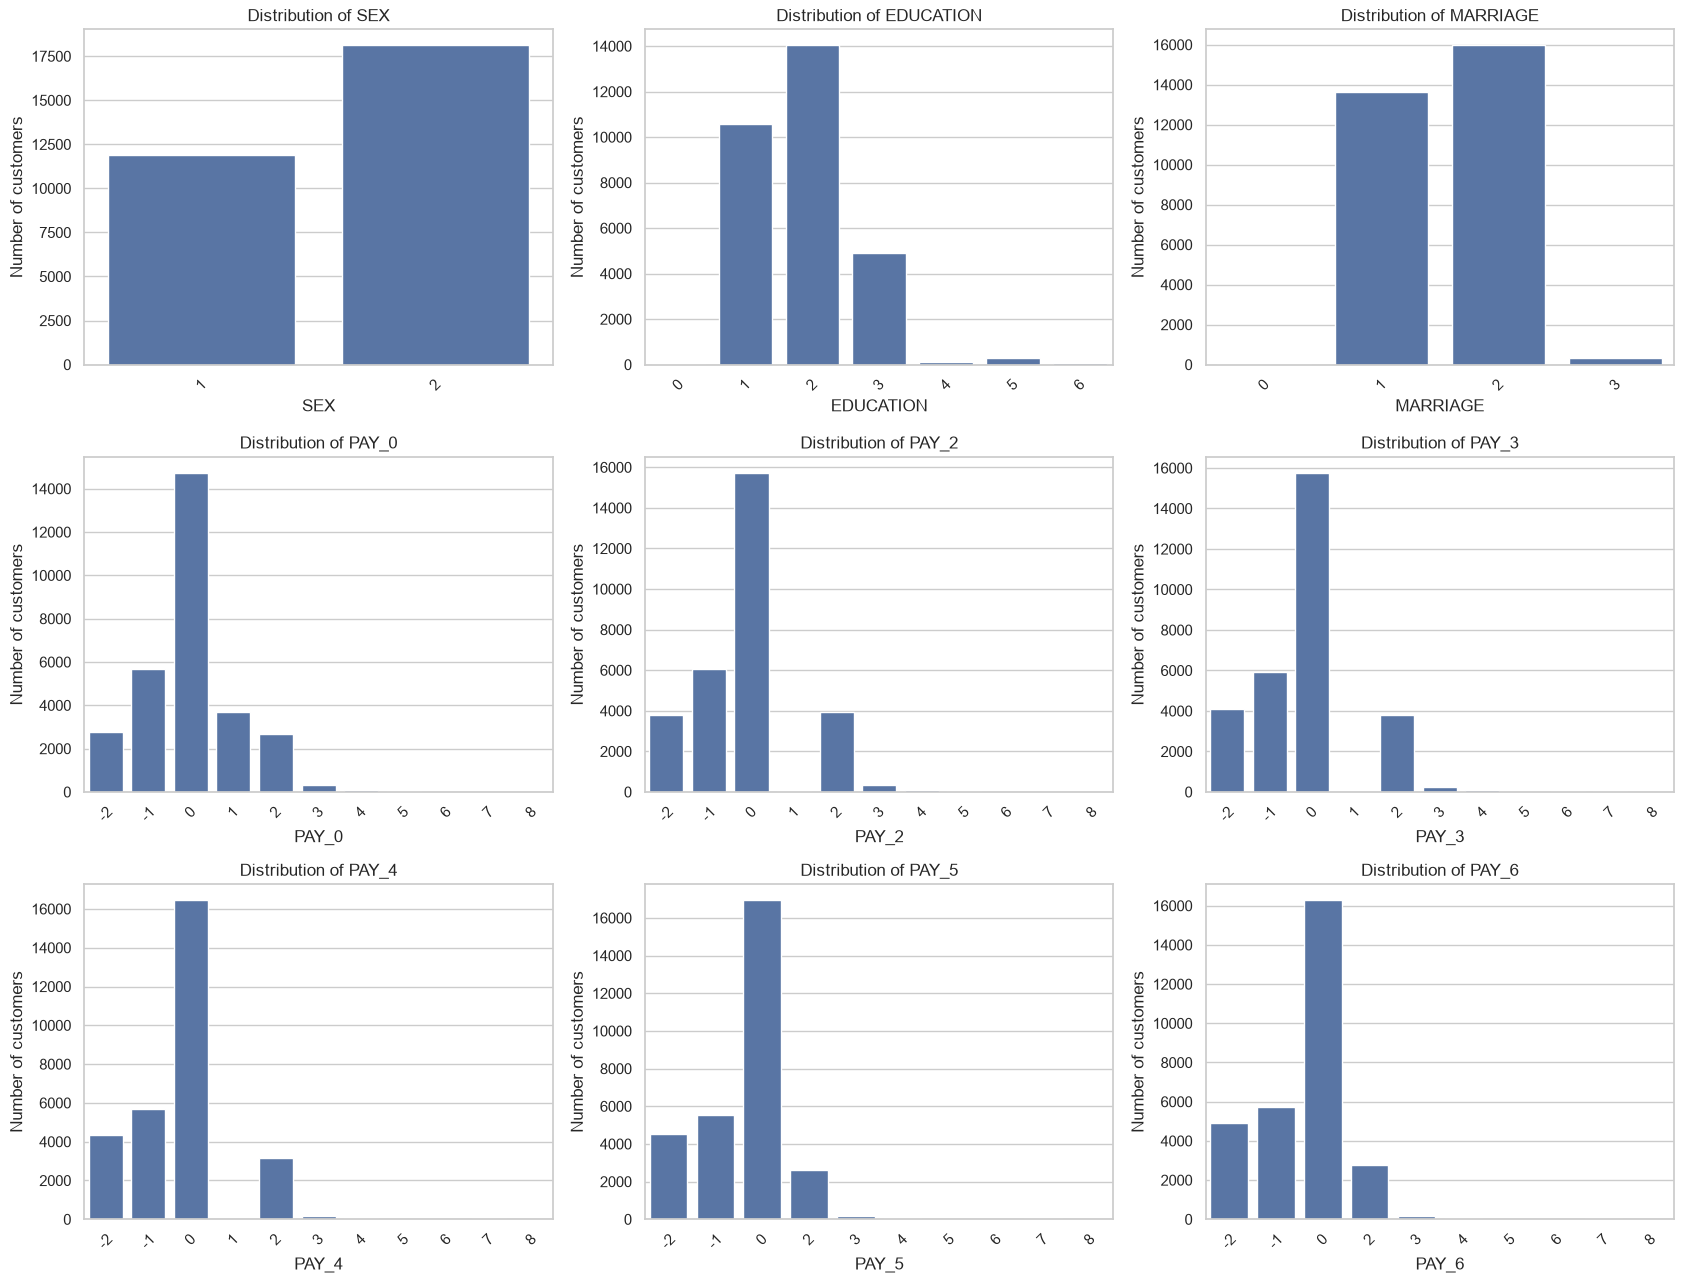

In [7]:
categorical_cols = [
    "SEX", "EDUCATION", "MARRIAGE",
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

fig, axes = plt.subplots(3, 3, figsize=(17, 13))

for col, ax in zip(categorical_cols, axes.flatten()):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of customers")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 4. Question 3: Six-month repayment patterns by future default status

The `PAY` columns are repayment-status codes, so calculating their arithmetic average can be misleading. Instead, this analysis calculates the percentage of customers with a **positive repayment-status code** (a recorded delay category) in each month.

For this dataset, the month mapping is:
- `PAY_6`: April
- `PAY_5`: May
- `PAY_4`: June
- `PAY_3`: July
- `PAY_2`: August
- `PAY_0`: September

The values `-2`, `-1` and `0` are not counted as positive delay codes here. This does not mean they all have the same meaning.

In [9]:
pay_cols = ["PAY_6", "PAY_5", "PAY_4", "PAY_3", "PAY_2", "PAY_0"]
months = ["April", "May", "June", "July", "August", "September"]

# True where the repayment-status code indicates a positive delay category
has_delay = df[pay_cols].ge(1)

# Calculate the percentage with a positive delay code in each month,
# separately for customers who did and did not default in the following month.
monthly_delay_rates = (
    has_delay.groupby(df[target_col])
    .mean()
    .mul(100)
)

monthly_delay_rates.columns = months
monthly_delay_rates.index = ["Did Not Default", "Defaulted"]

display(monthly_delay_rates.round(2))

,April,May,June,July,August,September
Did Not Default,6.28,5.65,6.98,8.61,8.40,14.51
Defaulted,24.28,24.85,28.32,33.18,37.31,51.67


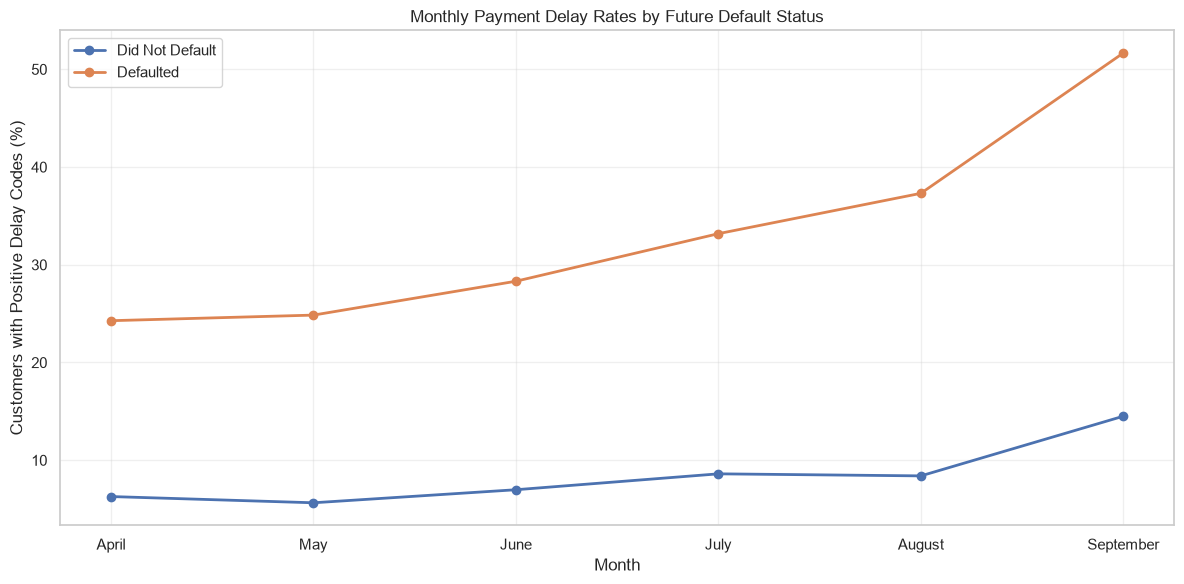

In [10]:
plt.figure(figsize=(12, 6))

for status, label in [(0, "Did Not Default"), (1, "Defaulted")]:
    plt.plot(
        months,
        monthly_delay_rates.loc[
            "Did Not Default" if status == 0 else "Defaulted"
        ],
        marker="o",
        linewidth=2,
        label=label
    )

plt.title("Monthly Payment Delay Rates by Future Default Status")
plt.xlabel("Month")
plt.ylabel("Customers with Positive Delay Codes (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### How to interpret Question 3

Compare the two lines month by month. If the line for customers who later defaulted is higher, that group had a larger percentage of customers with positive delay codes in that month.

Use the actual table and chart values to write the final interpretation after running the notebook. Do not claim that repayment delays cause default; this analysis shows an association. Also remember that the PAY codes are monthly status categories, not exact numbers of days late.

## 5. Question 5: Credit utilisation and default

Credit utilisation is the proportion of a customer's available credit limit represented by their statement balance.

\[
\text{Credit utilisation (\%)} =
\frac{\text{Statement balance}}{\text{Credit limit}} \times 100
\]

Here, `BILL_AMT1` is used as the latest statement balance and `LIMIT_BAL` is the credit limit. This is a simple utilisation measure based on the latest statement.

In [12]:
# Avoid division by zero or negative credit limits.
df["CREDIT_UTILISATION"] = np.where(
    df["LIMIT_BAL"] > 0,
    (df["BILL_AMT1"] / df["LIMIT_BAL"]) * 100,
    np.nan
)

# Summarise utilisation for each future-default group.
utilisation_summary = (
    df.groupby(target_col)["CREDIT_UTILISATION"]
    .agg(["count", "mean", "median"])
)

utilisation_summary.index = ["Did Not Default", "Defaulted"]
display(utilisation_summary.round(2))

,count,mean,median
Did Not Default,23364,40.49,26.75
Defaulted,6636,49.03,49.29


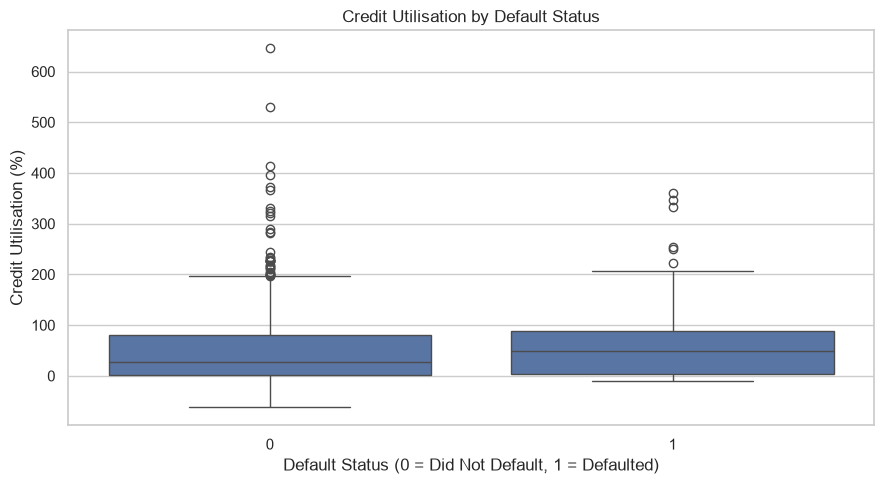

In [13]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x=target_col,
    y="CREDIT_UTILISATION"
)

plt.title("Credit Utilisation by Default Status")
plt.xlabel("Default Status (0 = Did Not Default, 1 = Defaulted)")
plt.ylabel("Credit Utilisation (%)")
plt.tight_layout()
plt.show()

### How to interpret Question 5

Compare the medians and the box plots for the two groups. A higher median among one group would indicate that its typical statement balance represented a larger share of its credit limit.

Check the summary table before writing the conclusion. Some calculated utilisation values may be above 100% if a statement balance exceeds the recorded credit limit; do not automatically delete these observations without investigating them.

Credit utilisation is an association, not proof that high utilisation causes default.

## 6. Key findings and conclusion

Complete this section after running all cells and checking the actual outputs.

- **Question 3:** State which group had higher monthly delay rates and whether the pattern persisted across the six months. Support the statement with values from the table.
- **Question 5:** State which group had the higher median credit utilisation, if the summary table supports that conclusion. Mention any overlap between the groups.
- **Overall:** Explain how repayment history and credit utilisation may help identify customers who could be at higher risk of default.

Do not insert numerical findings until the notebook has been run and the outputs have been checked.